# 03 — Preprocessing: find the person in every frame

**Part A — Traditional vision with machine learning** starts here (notebooks 03 to 08).

The course pipeline is: **image → descriptor (HOG, LBP, colour histogram) → classifier (KNN, SVM, RF)**.

**Problem:** a frame is 640 × 480 pixels and the person covers only a small part of it. A descriptor computed on the whole frame would mostly describe the **room** (walls, chairs, door), not the person's posture.

**Goal of this notebook:** for every frame, find a **box around the person**, and cut a small square image (a *crop*) of the person. Notebooks 04-08 compute their descriptors on these crops.

**Output:** `data/processed/person_boxes.csv`, one row per frame: video, frame, and the box `x, y, w, h` (empty if nobody was found).

In [1]:
from pathlib import Path
import re
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..") / "data" / "raw" / "urfd"
OUT = Path("..") / "data" / "processed" / "person_boxes.csv"

def frames_of(video):
    """All frame files of a video as (frame number, path), sorted by the number in the file name."""
    files = (ROOT / "rgb" / video).rglob("*.png")
    return sorted((int(re.search(r"-(\d+)\.png$", p.name).group(1)), p) for p in files)

def read_rgb(path):
    return cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)

labels = pd.concat([pd.read_csv(ROOT / "labels" / f"urfall-cam0-{k}.csv", header=None, usecols=[0, 1, 2])
                    for k in ["falls", "adls"]], ignore_index=True)
labels.columns = ["video", "frame", "frame_label"]
labels["phase"] = labels.frame_label.map({-1: "not lying", 0: "falling", 1: "lying"})

💡 **Interpretation:** setup only: paths, a function to list a video's frames in the right order, and the frame labels (not lying / falling / lying).

## Step 1 — First idea: the HOG people detector from the course

The course (slide 118) shows OpenCV's ready-made **HOG + SVM people detector** (Dalal & Triggs, 2005). Let us try it on frames from the 30 fall videos: 60 random frames per phase.

HOG people detector finds someone in: {'not lying': '93%', 'falling': '62%', 'lying': '50%'}


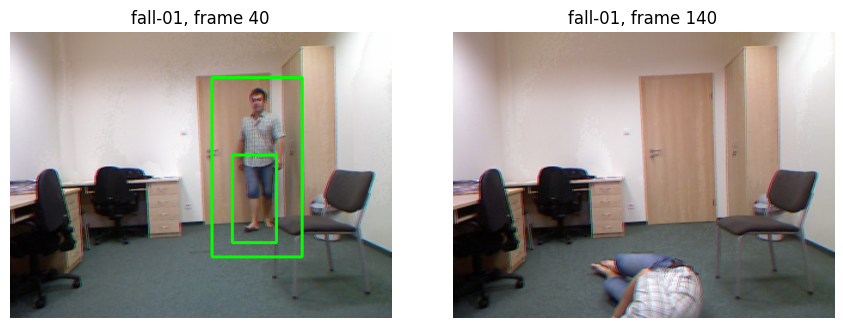

In [2]:
hog = cv2.HOGDescriptor()
hog.setSVMDetector(cv2.HOGDescriptor_getDefaultPeopleDetector())

def hog_people(image_rgb):
    rects, _ = hog.detectMultiScale(image_rgb, winStride=(8, 8), padding=(16, 16), scale=1.05)
    return rects

files = {v: dict(frames_of(v)) for v in labels.video.unique()}
rate = {}
for phase in ["not lying", "falling", "lying"]:
    sample = labels[(labels.phase == phase) & labels.video.str.startswith("fall")].sample(60, random_state=0)
    rate[phase] = np.mean([len(hog_people(read_rgb(files[r.video][r.frame]))) > 0 for r in sample.itertuples()])
print("HOG people detector finds someone in:", {k: f"{v:.0%}" for k, v in rate.items()})

fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
for ax, n in zip(axes, [40, 140]):
    image = read_rgb(files["fall-01"][n])
    for (x, y, w, h) in hog_people(image):
        cv2.rectangle(image, (x, y), (x + w, y + h), (0, 255, 0), 3)
    ax.imshow(image); ax.axis("off"); ax.set_title(f"fall-01, frame {n}")
plt.tight_layout(); plt.show()

💡 **Interpretation:** the detector finds the standing person (**93%**) but often misses them while falling (**62%**) and lying (**50%**): its SVM was trained on **upright pedestrians**.
In frame 40 it even gives two boxes for one person, and in frame 140 (lying) none: it fails exactly on the frames that matter for a fall.

## Step 2 — Background subtraction: the background is the *median* image

The camera **does not move**, so everything that changes between frames is the person. Idea:
1. build an image of the **empty room** (the background);
2. pixels that differ from it belong to the person.

To get the background we take, for every pixel, the **median** of its values over the video (one frame out of 5 is enough). The person moves, so at a given pixel they are present only a minority of the time, and the median keeps the room's colour.

We first tried OpenCV's adaptive model (MOG2), but it learns the first frames as background: when the person is already in the room at the start, a "ghost" stays at their starting place. The median avoids that.

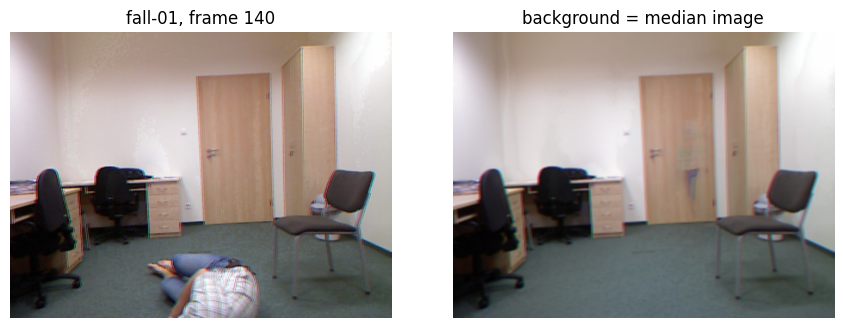

In [3]:
def background_of(video):
    images = [cv2.GaussianBlur(cv2.imread(str(p)), (5, 5), 0) for _, p in frames_of(video)[::5]]
    return np.median(np.stack(images), axis=0).astype(np.uint8)

bg = background_of("fall-01")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
axes[0].imshow(read_rgb(files["fall-01"][140])); axes[0].set_title("fall-01, frame 140")
axes[1].imshow(cv2.cvtColor(bg, cv2.COLOR_BGR2RGB)); axes[1].set_title("background = median image")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

💡 **Interpretation:** the median image is the **empty room**: the person disappeared because they never stay long in one place. Only a faint trace remains in front of the door,
where the person stood for a long time at the start; it creates the small white spot we will see in the mask.

## Step 3 — From the difference to a box

For each frame:
1. **blur** slightly (Gaussian 5 × 5) to remove pixel noise from the camera;
2. **difference** with the background; a pixel is "person" if it differs by more than **25** (out of 255) in any colour channel → a black-and-white **mask**;
3. **clean the mask** with two morphological operations: *opening* removes small isolated white dots, *closing* fills small holes inside the person;
4. keep the **largest white region** (if bigger than 800 pixels) and take its **bounding box**.

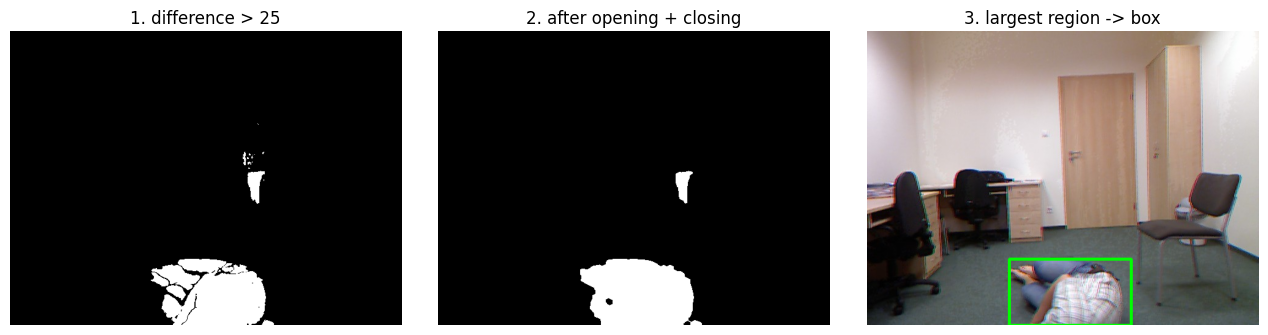

box (x, y, w, h): (232, 372, 199, 108)


In [4]:
THRESHOLD, MIN_AREA = 25, 800
KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

def person_mask(image_bgr, bg):
    diff = cv2.absdiff(cv2.GaussianBlur(image_bgr, (5, 5), 0), bg).max(axis=2)
    raw = (diff > THRESHOLD).astype(np.uint8) * 255
    clean = cv2.morphologyEx(raw, cv2.MORPH_OPEN, KERNEL)
    clean = cv2.morphologyEx(clean, cv2.MORPH_CLOSE, KERNEL, iterations=2)
    return raw, clean

def box_of(mask):
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contours = [c for c in contours if cv2.contourArea(c) > MIN_AREA]
    return cv2.boundingRect(max(contours, key=cv2.contourArea)) if contours else None

image = cv2.imread(str(files["fall-01"][140]))
raw, clean = person_mask(image, bg)
x, y, w, h = box_of(clean)
boxed = read_rgb(files["fall-01"][140]); cv2.rectangle(boxed, (x, y), (x + w, y + h), (0, 255, 0), 3)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
for ax, im, title in zip(axes, [raw, clean, boxed], ["1. difference > 25", "2. after opening + closing", "3. largest region -> box"]):
    ax.imshow(im, cmap="gray"); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()
print("box (x, y, w, h):", (x, y, w, h))

💡 **Interpretation:** the raw difference shows the lying person plus noise; opening + closing make one clean region, and the small spot near the door is ignored because we keep only the **largest** region.
The box (199 × 108 px) is **wider than tall**: the shape of the box alone already says *lying*.

## Step 4 — All 70 videos

This takes a few minutes. The result is saved, so if `person_boxes.csv` already exists we just load it.

In [5]:
def boxes_of(video):
    bg = background_of(video)
    rows = []
    for number, path in frames_of(video):
        box = box_of(person_mask(cv2.imread(str(path)), bg)[1])
        rows.append((video, number) + (box if box else (np.nan,) * 4))
    return rows

if OUT.exists():
    boxes = pd.read_csv(OUT)
else:
    rows = []
    for i, video in enumerate(sorted(files), 1):
        rows += boxes_of(video)
        print(f"[{i}/{len(files)}] {video}", end="  ", flush=True)
    boxes = pd.DataFrame(rows, columns=["video", "frame", "x", "y", "w", "h"])
    boxes.to_csv(OUT, index=False)
print(); print(boxes.shape)


(11936, 6)


💡 **Interpretation:** one box (or an empty row) for each of the 11,936 frames: 6 columns (video, frame, x, y, w, h), small enough to reload in a second in the next notebooks.

## Step 5 — How often is the person found?

Same table as for MediaPipe in notebook 09, so the two can be compared. We also check that the box is in the **right place**: when MediaPipe found the person, is the middle of their hips inside our box?

In [6]:
b = boxes.merge(labels, on=["video", "frame"], how="left")
b["found"] = b.x.notna()
b["kind"] = b.video.str.split("-").str[0]
b["phase"] = b.phase.fillna("no label")
print(f"person found in {b.found.mean():.0%} of all frames")
print(b.pivot_table(index="kind", columns="phase", values="found", aggfunc="mean").round(2))

skel = pd.read_csv(Path("..") / "data" / "processed" / "skeletons.csv",
                   usecols=["video", "frame", "detected", "l_hip_x", "r_hip_x", "l_hip_y", "r_hip_y"])
s = b.merge(skel, on=["video", "frame"])
s = s[s.detected.astype(bool) & s.found]
hip_x, hip_y = (s.l_hip_x + s.r_hip_x) / 2 * 640, (s.l_hip_y + s.r_hip_y) / 2 * 480
inside = (hip_x.between(s.x - 10, s.x + s.w + 10)) & (hip_y.between(s.y - 10, s.y + s.h + 10))
print(f"hips inside the box: {inside.mean():.0%} of the frames where both methods found someone")

person found in 94% of all frames
phase  falling  lying  no label  not lying
kind                                      
adl        1.0   0.92      0.55       0.94
fall       1.0   1.00       NaN       1.00


hips inside the box: 93% of the frames where both methods found someone


💡 **Interpretation:** the person is found in **94%** of the frames (MediaPipe: 82%), and in **100%** of the fall-video frames, *including lying* (MediaPipe: 78%): a moving body is easier to find than a body pose.
The box is in the right place: the hips found by MediaPipe are inside it in **93%** of the frames.

video
adl-18    0.60
adl-22    0.62
adl-21    0.65
adl-19    0.66
adl-23    0.67
Name: found, dtype: float64

of the 693 frames without a box, 25% are 'no label' frames


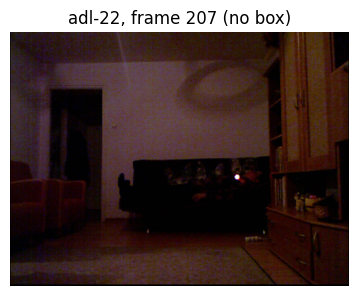

In [7]:
per_video = b.groupby("video").found.mean().sort_values()
print(per_video.head(5).round(2))
missing = b[~b.found]
print(f"\nof the {len(missing)} frames without a box, {(missing.phase == 'no label').mean():.0%} are 'no label' frames")
fig, ax = plt.subplots(figsize=(4.5, 3.3))
ax.imshow(read_rgb(files["adl-22"][207])); ax.set_title("adl-22, frame 207 (no box)"); ax.axis("off"); plt.show()

💡 **Interpretation:** the misses are concentrated in `adl-16`…`adl-23`, filmed in a **dark room**: a person in dark clothes on a black sofa or in front of a dark door barely differs from the background.
Only 25% of the misses are frames where the room is really empty (*no label*): low **contrast** is the main limit of background subtraction.

## Step 6 — Cut the person out: square crops

Descriptors and classifiers need images of the **same size**. We cut a **square** around the box (side = longest side of the box + 10% margin) and resize it to **128 × 128**.

Why a square and not just the box? Stretching the box to a square would make a lying person (wide box) and a standing person (tall box) look alike. In a square crop, **a standing person stays vertical and a lying person stays horizontal**, and that is exactly what we want the descriptors to see.

This `crop_person` function is copied into notebooks 04-08.

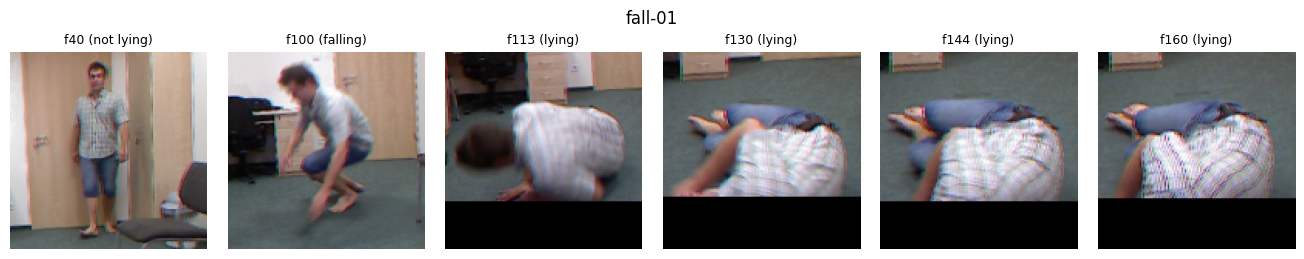

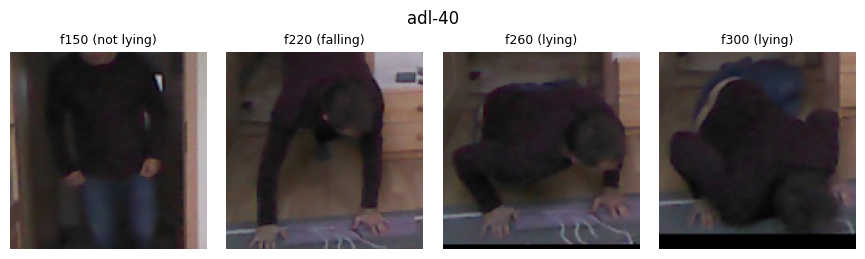

In [8]:
def crop_person(image, box, size=128):
    x, y, w, h = box
    side = int(max(w, h) * 1.1)
    cx, cy = x + w // 2, y + h // 2
    padded = cv2.copyMakeBorder(image, side, side, side, side, cv2.BORDER_CONSTANT, value=0)   # in case the square leaves the image
    x0, y0 = cx - side // 2 + side, cy - side // 2 + side
    return cv2.resize(padded[y0:y0 + side, x0:x0 + side], (size, size))

def show_crops(video, frame_numbers):
    rows = boxes[boxes.video == video].set_index("frame")
    fig, axes = plt.subplots(1, len(frame_numbers), figsize=(2.2 * len(frame_numbers), 2.6))
    for ax, n in zip(axes, frame_numbers):
        r = rows.loc[n]
        phase = b[(b.video == video) & (b.frame == n)].phase.iloc[0]
        ax.imshow(crop_person(read_rgb(files[video][n]), (int(r.x), int(r.y), int(r.w), int(r.h))))
        ax.set_title(f"f{n} ({phase})", fontsize=9); ax.axis("off")
    plt.suptitle(video); plt.tight_layout(); plt.show()

show_crops("fall-01", [40, 100, 113, 130, 144, 160])
show_crops("adl-40", [150, 220, 260, 300])

💡 **Interpretation:** in the crops a standing person is **vertical** and a lying person **horizontal**, which is what HOG must capture. Black bands appear when the person touches the **edge of the image** (nothing to cut there).
Parts close to the background colour can be lost (in `adl-40` f150 the dark hair against the dark door): the crops are good, not perfect.

## Step 7 — A first clue: the shape of the box

Before any descriptor, the box itself already says something: its **width / height** ratio.

In [9]:
b["width_over_height"] = b.w / b.h
b[b.phase != "no label"].groupby("phase").width_over_height.median().loc[["not lying", "falling", "lying"]].round(2)

phase
not lying    0.54
falling      0.85
lying        1.27
Name: width_over_height, dtype: float64

💡 **Interpretation:** the box is tall when the person is not lying (width/height **0.54**), almost square while falling (**0.85**) and wide when lying (**1.27**):
a posture can already be read from the silhouette's shape, and HOG will describe this shape in much more detail.

## What we learned

1. **Descriptors need the person, not the room.** The course's HOG people detector misses half of the lying frames (it was trained on upright pedestrians), so we used a classic alternative.
2. **Background subtraction with a median background** finds the person in **94%** of frames and in **100%** of the fall frames, more often than MediaPipe (82%), with simple steps: blur → difference → threshold → opening/closing → largest region → box.
3. **Limits:** low contrast (dark room, dark clothes, black sofa) hides the person in some ADL videos; the method needs a **fixed camera**, and a person who stays still for most of the video would become part of the background.
4. **Square 128 × 128 crops** keep the person's orientation (vertical vs horizontal), and the box shape already separates the phases (width/height 0.54 → 0.85 → 1.27).

**Next notebook (04):** HOG descriptors on these crops, classified with KNN, SVM and Random Forest.